<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and recorded data](README.md)

# 01 · How much does a pit-adjacent lap filter change a stint summary?

A lap-time median depends on which laps it includes. We will inspect **Max Verstappen, 2024 Chinese Grand Prix (round 5)**, split his lap sequence at recorded pit stops, and compare summaries with and without the stop lap and immediately following lap.

The default replays **complete public Jolpica-F1 responses** recorded for this notebook, with the unchanged real VGI worker still fetching and parsing them. It is not synthetic data. A tested live mode requests the same finished race. Pit-stop boundaries are useful grouping rules; they do not by themselves measure tyre effects, clear-air pace or driver performance.

## Choose a data mode and one analytical filter

`DATA_MODE` is `"replay"` by default or `"live"` for the same fixed season, round and driver. Replay has exact coverage and fails unsupported requests. Live uses the official Jolpica endpoint and never falls back to replay.

`EXCLUDE_PIT_ADJACENT=True` excludes each recorded stop lap and the next lap from **summaries only**. Raw laps stay visible. The one-parameter experiment changes only **True → False**, retaining the data mode. Predict more included laps; the direction of a median change depends on the values. Restart the kernel and Run All after editing.

In [1]:
DATA_MODE = "replay"  # "replay" or "live"; fixed 2024 Chinese GP / max_verstappen
EXCLUDE_PIT_ADJACENT = True  # Experiment: False; never changes source acquisition

In [2]:
import hashlib
import json
import os
from datetime import UTC, datetime
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from replay_source import ReplaySource

assert DATA_MODE in {"replay", "live"} and type(EXCLUDE_PIT_ADJACENT) is bool
manifest = json.loads(Path("fixtures/manifest.json").read_text())
previous_env = {key: os.environ.get(key) for key in ["F1_JOLPICA_BASE_URL", "F1_OPENF1_BASE_URL"]}
replay = ReplaySource(Path("fixtures")) if DATA_MODE == "replay" else None
os.environ["F1_JOLPICA_BASE_URL"] = replay.url if replay else "https://api.jolpi.ca/ergast/f1"
os.environ["F1_OPENF1_BASE_URL"] = "https://api.openf1.org/v1"
os.environ["PLOOMBER_STATS_ENABLED"] = "false"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"Jolpica-F1 · CC BY-NC-SA 4.0 · {DATA_MODE.upper()} · Chinese GP 2024-04-21 · Max Verstappen · lap times in seconds",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.06, 1, 0.98))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-f1/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-f1/notebooks/pyproject.toml.

## Attach the Git-tagged worker and materialize bounded race calls

The package is not on PyPI. The literal `uvx` command installs the published Git tag into its cache, with tested SDK/RPC/HTTP/Arrow versions, and needs no local worker checkout. The replay companion serves only two hash-verified response bodies on a loopback port. In live mode, inherited alternate-source settings are replaced by the official endpoints.

The lap call includes `driver_id` **as an API argument**, avoiding a whole-field timing request. Pit stops are requested for one race and then filtered locally for the selected driver. These are bounded season/round requests, not an unbounded history plus LIMIT. Materialization prevents subsequent charting from repeating worker calls.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'f1' AS f1 (
    TYPE vgi,
    LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-f1@v0.2.0 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with httpx==0.28.1 --with pyarrow==25.0.1 vgi-f1'
);

,Success


In [4]:
request_started = datetime.now(UTC).isoformat()

In [5]:
%%sql
CREATE TABLE laps_source AS
SELECT * FROM f1.main.lap_times(2024,5,driver_id:='max_verstappen');
CREATE TABLE stops_source AS
SELECT * FROM f1.main.pit_stops(2024,5);
CREATE TABLE driver_stops AS
SELECT * FROM stops_source WHERE driver_id='max_verstappen';

,Count


In [6]:
retrieved_at = datetime.now(UTC).isoformat()

## Verify coverage and separate clocks from durations

Lap times and pit-lane durations are measured in **seconds**, with decimal precision retained in SQL. The pit-stop `time` field is an upstream wall-clock string, not a UTC timestamp; we use lap numbers to join and do not convert it to an invented instant. Pit durations cover lane entry to exit, not just stationary service.

The original response capture bounds live in the manifest. They differ from this execution's retrieval interval, which contacts the loopback replay server in replay mode. Empty, missing or duplicated lap observations stop the analysis. A continuous returned lap sequence checks this dataset, not every aspect of race timing completeness.

In [7]:
%%sql coverage <<
SELECT (SELECT count(*) FROM laps_source) AS laps,
       (SELECT count(DISTINCT lap) FROM laps_source) AS unique_laps,
       (SELECT min(lap) FROM laps_source) AS first_lap,
       (SELECT max(lap) FROM laps_source) AS last_lap,
       (SELECT count(*) FROM laps_source WHERE lap_time_seconds IS NULL OR lap_time_seconds<=0) AS invalid_times,
       (SELECT count(*) FROM stops_source) AS field_pit_stops,
       (SELECT count(*) FROM driver_stops) AS driver_pit_stops;

In [8]:
%%sql stops <<
SELECT stop,lap,duration_seconds FROM driver_stops ORDER BY stop;

In [9]:
display(coverage)
display(stops)
d = coverage.iloc[0]
assert d.laps > 0 and d.laps == d.unique_laps and d.invalid_times == 0
assert d.first_lap == 1 and d.laps == d.last_lap - d.first_lap + 1
assert not stops.empty and stops.stop.is_unique and stops.lap.is_unique
assert stops.lap.between(d.first_lap, d.last_lap).all()
assert (
    con.execute(
        "SELECT count(*) FROM laps_source WHERE season<>2024 OR round<>5 OR driver_id<>'max_verstappen'"
    ).fetchone()[0]
    == 0
)
raw_laps = con.execute("SELECT * FROM laps_source ORDER BY lap").fetchdf()
raw_stops = con.execute("SELECT * FROM stops_source ORDER BY driver_id,stop").fetchdf()
source_hash = hashlib.sha256(
    (raw_laps.to_json(orient="records") + raw_stops.to_json(orient="records")).encode()
).hexdigest()
if replay:
    assert len(replay.requests) == 2, "Expected exactly the two covered retrievals."
    provenance = f"Recorded response UTC bounds: **{manifest['entries'][0]['retrieval_start_utc']} → {manifest['entries'][-1]['retrieval_end_utc']}**. Hashes verified; two replay requests served."
else:
    provenance = "Live requests used the official Jolpica endpoint; historical responses may have been revised since recording."
prose(
    f"**{DATA_MODE.upper()}** · {provenance} This execution's retrieval UTC bounds: **{request_started} → {retrieved_at}**. "
    f"Returned **{int(d.laps)} driver laps**, **{int(d.field_pit_stops)} field pit stops**, and **{int(d.driver_pit_stops)} stops** for this driver. "
    f"Materialized-data fingerprint: `{source_hash}`."
)

,laps,unique_laps,first_lap,last_lap,invalid_times,field_pit_stops,driver_pit_stops
0,56,56,1,56,0,40,2


,stop,lap,duration_seconds
0,1,13,22.456
1,2,23,22.270


**REPLAY** · Recorded response UTC bounds: **2026-11-14T06:39:00.960851+00:00 → 2026-11-14T06:39:02.076218+00:00**. Hashes verified; two replay requests served. This execution's retrieval UTC bounds: **2026-11-14T06:42:45.635190+00:00 → 2026-11-14T06:42:45.715844+00:00**. Returned **56 driver laps**, **40 field pit stops**, and **2 stops** for this driver. Materialized-data fingerprint: `e32f3542d0d5638c11c05f92b61500baaa281c1578cb09facd0e68d48d84c742`.

## Define stint boundaries and the inclusion rule explicitly

A lap belongs to stint **1 + the number of stops on earlier laps**. The recorded stop lap therefore closes the previous group; the following lap opens the next group. These groups do not identify tyre compound or tyre age.

We mark a lap as pit-adjacent when its number equals a stop lap or that stop lap plus one. With the filter enabled, those marked laps stay in the raw plot but leave the summary. The opening lap, traffic, flags, safety-car periods, weather, fuel changes and other slow laps remain; there is no claim of clean racing pace.

In [10]:
%%sql
CREATE TABLE analyzed_laps AS
SELECT l.*,
       1+(SELECT count(*) FROM driver_stops s WHERE s.lap<l.lap) AS stint,
       EXISTS(SELECT 1 FROM driver_stops s WHERE l.lap=s.lap OR l.lap=s.lap+1) AS pit_adjacent,
       NOT ({{EXCLUDE_PIT_ADJACENT}} AND EXISTS(
         SELECT 1 FROM driver_stops s WHERE l.lap=s.lap OR l.lap=s.lap+1
       )) AS included
FROM laps_source l;

,Count


In [11]:
%%sql laps <<
SELECT lap,CAST(lap_time_seconds AS DOUBLE) AS lap_seconds,stint,pit_adjacent,included
FROM analyzed_laps ORDER BY lap;

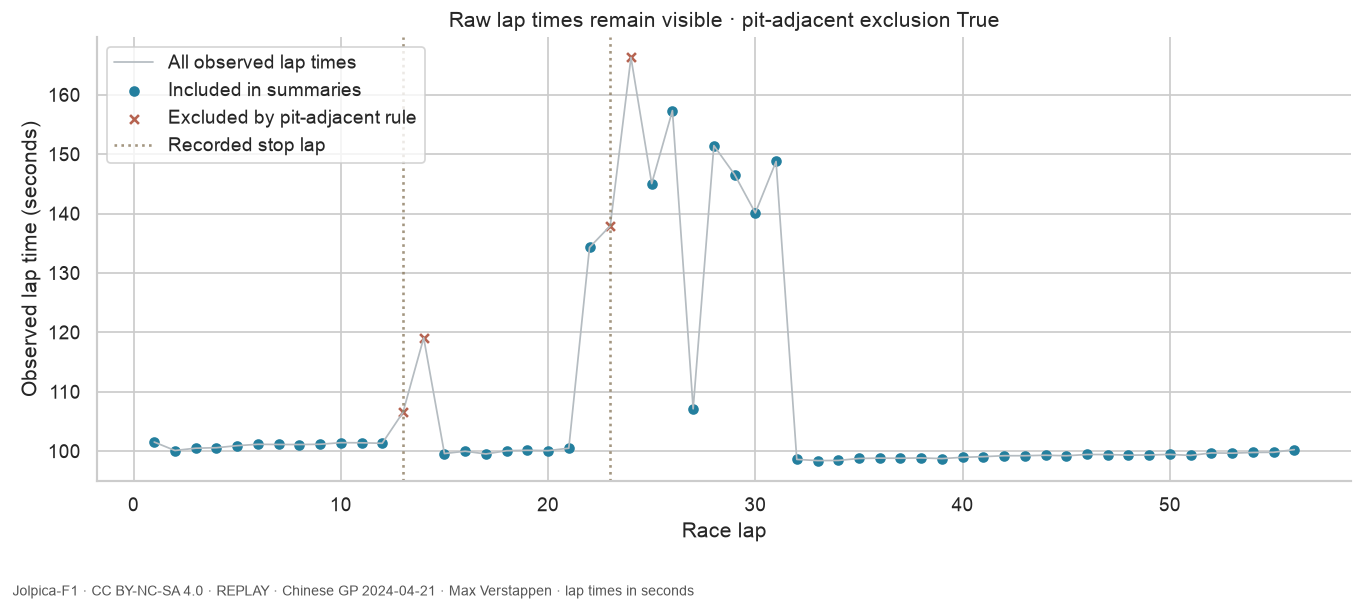

In [12]:
assert len(laps) == int(d.laps)
assert laps.included.equals(~laps.pit_adjacent if EXCLUDE_PIT_ADJACENT else pd.Series(True, index=laps.index))
assert laps.stint.min() == 1 and laps.stint.max() == len(stops) + 1
fig, ax = plt.subplots(figsize=(11, 5.0))
ax.plot(laps.lap, laps.lap_seconds, color="#b5bcc1", linewidth=1, label="All observed lap times")
for included, color, marker, label in [
    (True, "#247f9e", "o", "Included in summaries"),
    (False, "#b66350", "x", "Excluded by pit-adjacent rule"),
]:
    rows = laps[laps.included.eq(included)]
    if not rows.empty:
        ax.scatter(rows.lap, rows.lap_seconds, color=color, marker=marker, s=26, label=label)
for i, r in enumerate(stops.itertuples()):
    ax.axvline(
        r.lap, color="#8c7c61", linestyle=":", alpha=0.8, label="Recorded stop lap" if i == 0 else None
    )
ax.set(
    xlabel="Race lap",
    ylabel="Observed lap time (seconds)",
    title=f"Raw lap times remain visible · pit-adjacent exclusion {EXCLUDE_PIT_ADJACENT}",
)
ax.legend(loc="upper left")
finish(fig)

## Compare the retained distributions, keeping sample sizes visible

Each summary reports the number of observed, excluded and retained laps. The quartile interval describes the retained lap-time distribution; it is not a confidence interval. A median or lower quartile changes with the inclusion rule and race conditions, so these groups should not be ranked as causal tyre or driver effects.

In [13]:
%%sql stint_summary <<
SELECT stint,min(lap) AS first_observed_lap,max(lap) AS last_observed_lap,
       count(*) AS observed_laps,count(*) FILTER(WHERE NOT included) AS excluded_laps,
       count(*) FILTER(WHERE included) AS retained_laps,
       CAST(quantile_cont(lap_time_seconds,0.25) FILTER(WHERE included) AS DOUBLE) AS q1_seconds,
       CAST(median(lap_time_seconds) FILTER(WHERE included) AS DOUBLE) AS median_seconds,
       CAST(quantile_cont(lap_time_seconds,0.75) FILTER(WHERE included) AS DOUBLE) AS q3_seconds
FROM analyzed_laps GROUP BY stint ORDER BY stint;

,stint,first_observed_lap,last_observed_lap,observed_laps,excluded_laps,retained_laps,q1_seconds,median_seconds,q3_seconds
0,1,1,13,13,1,12,100.832,101.132,101.338
1,2,14,23,10,2,8,99.886,100.075,100.226
2,3,24,56,33,1,32,98.930,99.337,99.917


The rule retains **52 of 56 laps**, excluding **4**. stint 1 median **101.132s** from 12 laps; stint 2 median **100.075s** from 8 laps; stint 3 median **99.337s** from 32 laps. These are observed timing summaries under the chosen rule, not estimates of otherwise equal racing conditions.

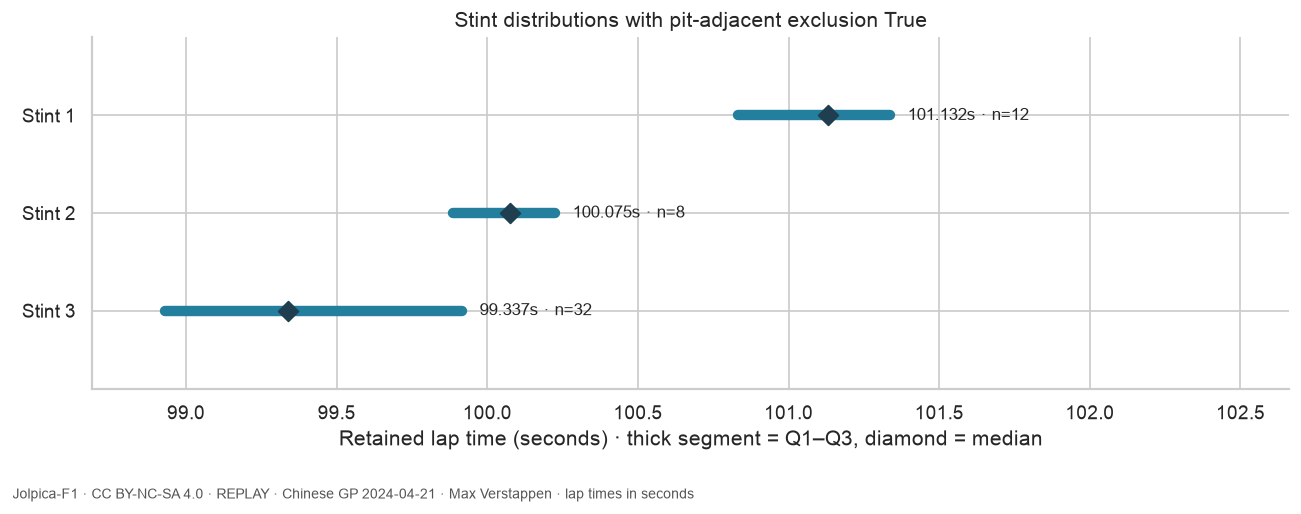

In [14]:
display(stint_summary)
assert stint_summary.observed_laps.sum() == len(laps)
assert (stint_summary.excluded_laps + stint_summary.retained_laps).equals(stint_summary.observed_laps)
assert stint_summary.retained_laps.gt(0).all()
assert (
    stint_summary.q1_seconds.le(stint_summary.median_seconds).all()
    and stint_summary.median_seconds.le(stint_summary.q3_seconds).all()
)
prose(
    f"The rule retains **{int(stint_summary.retained_laps.sum())} of {len(laps)} laps**, excluding "
    f"**{int(stint_summary.excluded_laps.sum())}**. "
    + "; ".join(
        f"stint {int(r.stint)} median **{r.median_seconds:.3f}s** from {int(r.retained_laps)} laps"
        for r in stint_summary.itertuples()
    )
    + ". These are observed timing summaries under the chosen rule, not estimates of otherwise equal racing conditions."
)
fig, ax = plt.subplots(figsize=(10.5, 4.2))
for r in stint_summary.itertuples():
    ax.plot(
        [r.q1_seconds, r.q3_seconds], [r.stint, r.stint], color="#247f9e", linewidth=6, solid_capstyle="round"
    )
    ax.scatter([r.median_seconds], [r.stint], color="#1f3f50", marker="D", s=65, zorder=3)
    ax.annotate(
        f"{r.median_seconds:.3f}s · n={int(r.retained_laps)}",
        (r.q3_seconds, r.stint),
        xytext=(10, 0),
        textcoords="offset points",
        va="center",
        fontsize=10,
    )
span = max(float(stint_summary.q3_seconds.max() - stint_summary.q1_seconds.min()), 1)
ax.set_xlim(stint_summary.q1_seconds.min() - 0.1 * span, stint_summary.q3_seconds.max() + 0.55 * span)
ax.set_yticks(stint_summary.stint, [f"Stint {int(x)}" for x in stint_summary.stint])
ax.invert_yaxis()
ax.margins(y=0.4)
ax.set(
    xlabel="Retained lap time (seconds) · thick segment = Q1–Q3, diamond = median",
    title=f"Stint distributions with pit-adjacent exclusion {EXCLUDE_PIT_ADJACENT}",
)
finish(fig)

## One change to test

Keep `DATA_MODE="replay"` and change only **`EXCLUDE_PIT_ADJACENT=True` to `False`** in a separate executed copy. The source fingerprint, raw lap sequence and stop laps must remain unchanged. More laps enter each summary where a marked lap exists; median and quartile changes depend on the observations. Restore **True** afterward.

A separate optional `DATA_MODE="live"` run exercises the same finished-race requests against Jolpica. It is a source check, not the filter experiment; compare fingerprints before interpreting a change. Attribution: [Jolpica-F1](https://github.com/jolpica/jolpica-f1), data and derived outputs under [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). This notebook is not affiliated with Formula 1 or the FIA.

In [15]:
con.execute("DETACH f1")
con.close()
if replay:
    replay.close()
for key, value in previous_env.items():
    if value is None:
        os.environ.pop(key, None)
    else:
        os.environ[key] = value

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and source attribution](README.md)